In [ ]:
! pip install torch

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

import matplotlib.pyplot as plt
import seaborn as sns

Chargement et préparation des données

In [ ]:
data = pd.read_csv("data/data_preprocessed.csv")
data_processed = data.sort_values(by='time_of_day')

In [5]:
# Découpage temporel : 70% / 15% / 15%
n = len(data)
train_end = int(0.7 * n)
val_end   = int(0.85 * n)

train_data = data.iloc[:train_end]
val_data   = data.iloc[train_end:val_end]
test_data  = data.iloc[val_end:]

X_train = train_data.drop(columns=["normality"])
y_train = train_data["normality"]

X_val = val_data.drop(columns=["normality"])
y_val = val_data["normality"]

X_test = test_data.drop(columns=["normality"])
y_test = test_data["normality"]

Entraînement en One-Class Learning

On conserve uniquement les données normales (0) pour l’apprentissage.

In [6]:
X_train_normal = X_train[y_train == 0]

Normalisation des données

In [7]:
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

Création des séquences temporelles

In [8]:
def create_sequences(X, seq_len=10):
    sequences = []
    for i in range(len(X) - seq_len + 1):
        sequences.append(X[i:i+seq_len])
    return np.array(sequences)

SEQ_LEN = 10

X_train_seq = create_sequences(X_train_normal, SEQ_LEN)
X_val_seq   = create_sequences(X_val_scaled, SEQ_LEN)
X_test_seq  = create_sequences(X_test_scaled, SEQ_LEN)

Conversion en tenseurs PyTorch

In [9]:
X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val_seq, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_seq, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor),
    batch_size=128,
    shuffle=True
)

Définition de l’Autoencodeur LSTM

In [10]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=16):
        super().__init__()

        self.encoder = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.encoder_fc = nn.Linear(hidden_dim, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, hidden_dim)
        self.decoder = nn.LSTM(hidden_dim, input_dim, batch_first=True)

    def forward(self, x):
        _, (h_n, _) = self.encoder(x)
        z = self.encoder_fc(h_n[-1])

        z = self.decoder_fc(z)
        z = z.unsqueeze(1).repeat(1, x.size(1), 1)

        out, _ = self.decoder(z)
        return out

Entraînement du modèle

In [11]:
model = LSTMAutoencoder(input_dim=X_train_tensor.shape[2])
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 30

for epoch in range(EPOCHS):
    model.train()
    loss_sum = 0

    for (x,) in train_loader:
        optimizer.zero_grad()
        x_hat = model(x)
        loss = criterion(x_hat, x)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {loss_sum/len(train_loader.dataset):.6f}")

Epoch [1/30] - Loss: 0.812908
Epoch [2/30] - Loss: 0.778385
Epoch [3/30] - Loss: 0.768440
Epoch [4/30] - Loss: 0.763394
Epoch [5/30] - Loss: 0.759199
Epoch [6/30] - Loss: 0.755562
Epoch [7/30] - Loss: 0.752207
Epoch [8/30] - Loss: 0.748675
Epoch [9/30] - Loss: 0.745056
Epoch [10/30] - Loss: 0.742028
Epoch [11/30] - Loss: 0.739404
Epoch [12/30] - Loss: 0.737377
Epoch [13/30] - Loss: 0.735389
Epoch [14/30] - Loss: 0.733488
Epoch [15/30] - Loss: 0.732036
Epoch [16/30] - Loss: 0.730725
Epoch [17/30] - Loss: 0.727810
Epoch [18/30] - Loss: 0.726797
Epoch [19/30] - Loss: 0.725155
Epoch [20/30] - Loss: 0.724718
Epoch [21/30] - Loss: 0.723506
Epoch [22/30] - Loss: 0.723225
Epoch [23/30] - Loss: 0.721869
Epoch [24/30] - Loss: 0.719742
Epoch [25/30] - Loss: 0.719417
Epoch [26/30] - Loss: 0.719463
Epoch [27/30] - Loss: 0.717403
Epoch [28/30] - Loss: 0.717270
Epoch [29/30] - Loss: 0.717493
Epoch [30/30] - Loss: 0.716769


Calcul de l’erreur de reconstruction

In [12]:
model.eval()
with torch.no_grad():
    val_pred  = model(X_val_tensor)
    test_pred = model(X_test_tensor)

val_errors = torch.mean((X_val_tensor - val_pred)**2, dim=(1,2)).numpy()
test_errors = torch.mean((X_test_tensor - test_pred)**2, dim=(1,2)).numpy()

Sélection du seuil optimal (F1-score)

In [13]:
percentiles = np.arange(95, 100, 0.1)

best_f1 = 0
best_thresh = None

y_val_aligned = y_val[SEQ_LEN-1:].values

for p in percentiles:
    thresh = np.percentile(val_errors, p)
    preds = (val_errors >= thresh).astype(int)
    f1 = f1_score(y_val_aligned, preds)

    if f1 > best_f1:
        best_f1 = f1
        best_thresh = thresh

print(f"Seuil optimal : {best_thresh:.6f} | F1 = {best_f1:.4f}")

Seuil optimal : 4.862094 | F1 = 0.1816


Évaluation finale

In [14]:
y_val_pred = (val_errors >= best_thresh).astype(int)
y_test_pred = (test_errors >= best_thresh).astype(int)

print("Validation :")
print(classification_report(y_val_aligned, y_val_pred))

print("Test :")
print(classification_report(y_test[SEQ_LEN-1:], y_test_pred))

Validation :
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     51110
           1       0.18      0.18      0.18      2574

    accuracy                           0.92     53684
   macro avg       0.57      0.57      0.57     53684
weighted avg       0.92      0.92      0.92     53684

Test :
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     53162
           1       0.19      0.89      0.31       522

    accuracy                           0.96     53684
   macro avg       0.60      0.93      0.65     53684
weighted avg       0.99      0.96      0.97     53684



In [19]:
print(f"AUC = {roc_auc_score(y_val_aligned, val_errors):.3f}")

AUC = 0.926


Visualisations

Courbe ROC

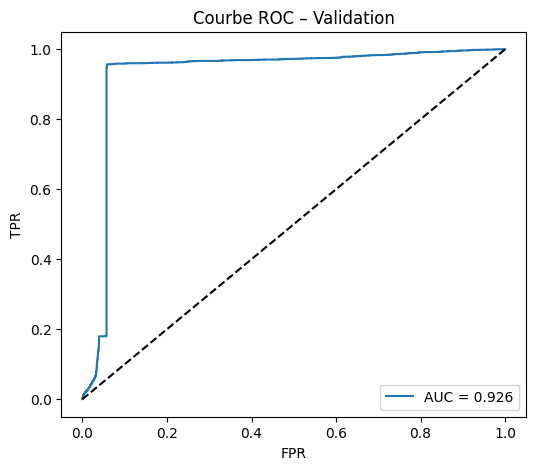

In [15]:
fpr, tpr, _ = roc_curve(y_val_aligned, val_errors)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_val_aligned, val_errors):.3f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Courbe ROC – Validation")
plt.legend()
plt.show()

Matrice de confusion

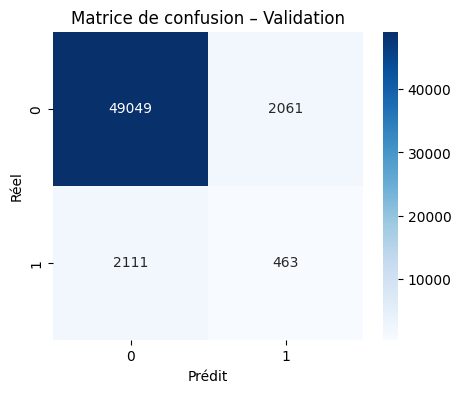

In [16]:
cm = confusion_matrix(y_val_aligned, y_val_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion – Validation")
plt.show()

Distribution des erreurs

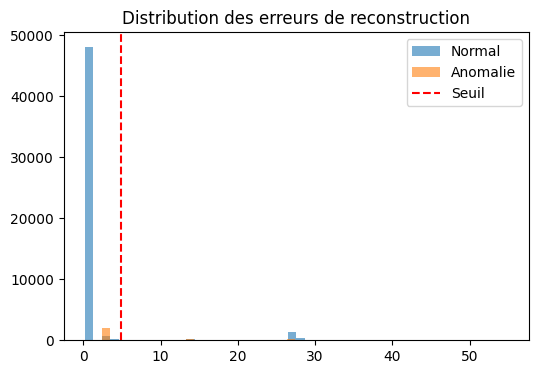

In [17]:
plt.figure(figsize=(6,4))
plt.hist(val_errors[y_val_aligned==0], bins=50, alpha=0.6, label="Normal")
plt.hist(val_errors[y_val_aligned==1], bins=50, alpha=0.6, label="Anomalie")
plt.axvline(best_thresh, color="red", linestyle="--", label="Seuil")
plt.legend()
plt.title("Distribution des erreurs de reconstruction")
plt.show()

Conclusion
- Modèle adapté aux anomalies temporelles